In [133]:
import os
from tqdm import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from functools import reduce
import statistics

In [17]:
sns.set_context("talk", font_scale=1.35)

# Function

In [80]:
L2_colors = {
   'CD4T_Naive':   '#5A1C1C',  # deep brownish-maroon
   'CD4T_Memory':  '#752211',  # deep brick red (darker, less orange)
   'Treg':         '#C45F30',  # lighter burnt orange-brown (more rusty)
   'CD8T_Naive':   '#730000',  # wine red
   'CD8T_Memory':  '#C0392B',  # classic tomato red
   'gdT':          '#E1573A',  # warm coral red
   'MAIT':         '#FF8C42',  # vivid orange
   'NK_bright':    '#F48C06',  # golden orange
   'NK_dim':       '#D95F02',  # reddish orange
   'B_Memory': '#0B5F2F', 
    'B_Naive': '#2D9A57', 
    'B_atypical': '#40BD5C', 
    'Plasma': '#7FC685',
   'cDC1': '#16376A',
    'cDC2': '#2B5CCD',
    'pDC': '#4A85E3', 
    'cM': '#3E8599', 
    'ncM': '#65B0C4', 
    'Progen': '#595959', 
    'Prolif': '#9F7F66',
    'ICC':'black'
}

L1_colors = {
   "B": "#2D6A3F",
   "Plasma": "#7FB685",
   "CD4T": "#6B1C1C",
   "CD8T": "#A13030",
   "gdT": "#E3735E",
   "MAIT": "#FFA07A",
   "NK": "#F47024",
   "cDC": "#284F8C",
   "pDC": "#4A75D3",
   "cM": "#3E8589",
   "ncM": "#65B0B4",
   "Progen": "#595959",
   "Prolif": "#907F66"
 }


# get data just use metadata csv

In [2]:
df=pd.read_csv("/data/processed/march2025/MultiVI_posttraining_RNA_Celltypist_VaryingClusteringResolution_manual_annots_filtered_meta.csv")
df.head()

,Unnamed: 0,Barcode,Well,Pool,best_sample,best_type,rna_pct_mt,atac_pct_mt,best_rna_ambient,best_atac_ambient,...,Cohort,Assignment,EUR,AFR,EAS,AMR,SAS_Admixture,RemoveRelated,RemoveRepeat,RemoveSex
0,XHLT1-POOL-XX1-SC1#GCCTGTGCATTTAAGC-1,GCCTGTGCATTTAAGC-1,XHLT1-POOL-XX1-SC1,XX1,CUPP_180,Singlet,0.32230,0.010880,0.374326,0.098096,...,ICC,EUR,0.982404,0.017576,0.000010,0.00001,0,False,False,False
1,XHLT1-POOL-XX1-SC1#GTTCATTTCCTCAGTC-1,GTTCATTTCCTCAGTC-1,XHLT1-POOL-XX1-SC1,XX1,CUPP_122,Singlet,0.03729,0.000142,0.109528,0.194794,...,ICC,AFR,0.000010,0.999970,0.000010,0.00001,0,False,False,False
2,XHLT1-POOL-XX1-SC1#GATGACTTCTGGTCCT-1,GATGACTTCTGGTCCT-1,XHLT1-POOL-XX1-SC1,XX1,CUPP_180,Singlet,0.07599,0.005590,0.113928,0.029881,...,ICC,EUR,0.982404,0.017576,0.000010,0.00001,0,False,False,False
3,XHLT1-POOL-XX1-SC1#TTGCAACAGAAAGGAA-1,TTGCAACAGAAAGGAA-1,XHLT1-POOL-XX1-SC1,XX1,_2325,Singlet,0.14220,0.011320,0.158853,0.041692,...,ICC,EUR,0.983998,0.000010,0.015982,0.00001,0,False,False,False
4,XHLT1-POOL-XX1-SC1#CGAATCTAGCTGAGGG-1,CGAATCTAGCTGAGGG-1,XHLT1-POOL-XX1-SC1,XX1,_0923,Singlet,0.09360,0.006472,0.088077,0.033778,...,ICC,EUR,0.973489,0.026491,0.000010,0.00001,0,False,False,False


In [57]:
df.columns

Index(['Unnamed: 0', 'Barcode', 'Well', 'Pool', 'best_sample', 'best_type',
       'rna_pct_mt', 'atac_pct_mt', 'best_rna_ambient', 'best_atac_ambient',
       'n_rna_umis', 'n_atac_frag', 'pct_tss', 'FRIP', 'pct_intronic',
       'leiden_MultiVIResolution_1', 'leiden_MultiVIResolution_0.5',
       'leiden_MultiVIResolution_1.2', 'leiden_MultiVIResolution_1.5',
       'leiden_MultiVIResolution_2', 'AIFI_L1_prediction', 'AIFI_L1_score',
       'AIFI_L2_prediction', 'AIFI_L2_score', 'AIFI_L3_prediction',
       'AIFI_L3_score', 'L0_manual', 'L1_manual', 'L2_manual', 'L3_manual',
       'VCF_ID', 'Age', 'Sex', 'Site', 'Asian', 'African', 'European',
       'Hispanic', 'NativeAmerican', 'PacificIslander', 'GenotypingArray',
       'PC1', 'PC2', 'PC3', 'Cohort', 'Assignment', 'EUR', 'AFR', 'EAS', 'AMR',
       'SAS_Admixture', 'RemoveRelated', 'RemoveRepeat', 'RemoveSex'],
      dtype='object')

In [4]:
df.shape

(1051508, 54)

In [30]:
df['best_type'].value_counts()

best_type
Singlet    1051508
Name: count, dtype: int64

# get counts of cells per donor

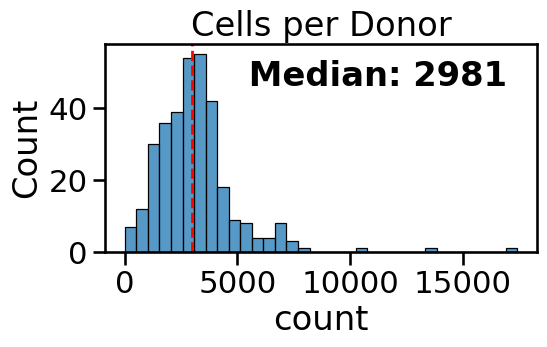

In [54]:
fig, ax = plt.subplots(figsize=(6, 4))
plt_df=pd.DataFrame(df.best_sample.value_counts())
plt_df['Donor']=plt_df.index

median_val = int(plt_df['count'].median())

sns.histplot(data=plt_df, x='count')
ax.axvline(median_val, color='red', linestyle='--', linewidth=2)
ax.text(
    x=median_val+2000, 
    y=ax.get_ylim()[1] * 0.8, 
    s=f' Median: {median_val}', 
    color='black', 
    fontweight='bold'
)


plt.title('Cells per Donor')
plt.tight_layout()

# get counts of cells per cell type

/tmp/ipykernel_1731/3465018930.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plt_df, y='L1_celltype',x='count',palette=L1_colors)


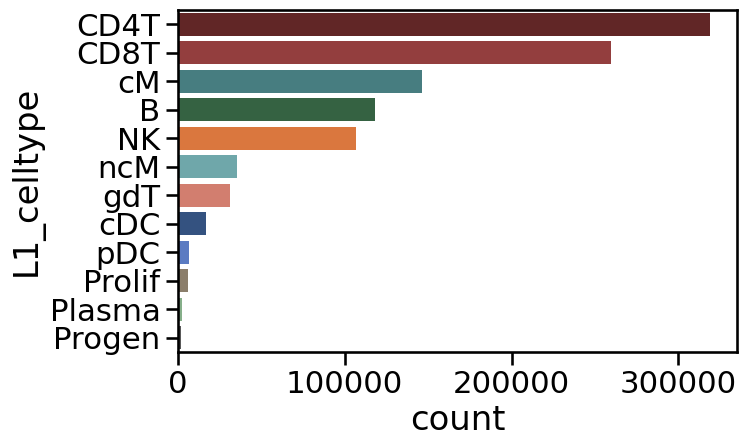

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
plt_df=pd.DataFrame(df.L1_manual.value_counts())
plt_df['L1_celltype']=plt_df.index
sns.barplot(data=plt_df, y='L1_celltype',x='count',palette=L1_colors)
#plt.title('L1 Cell Types')
plt.tight_layout()

/tmp/ipykernel_1731/2296765841.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plt_df, y='L2_celltype',x='count',palette=L2_colors)


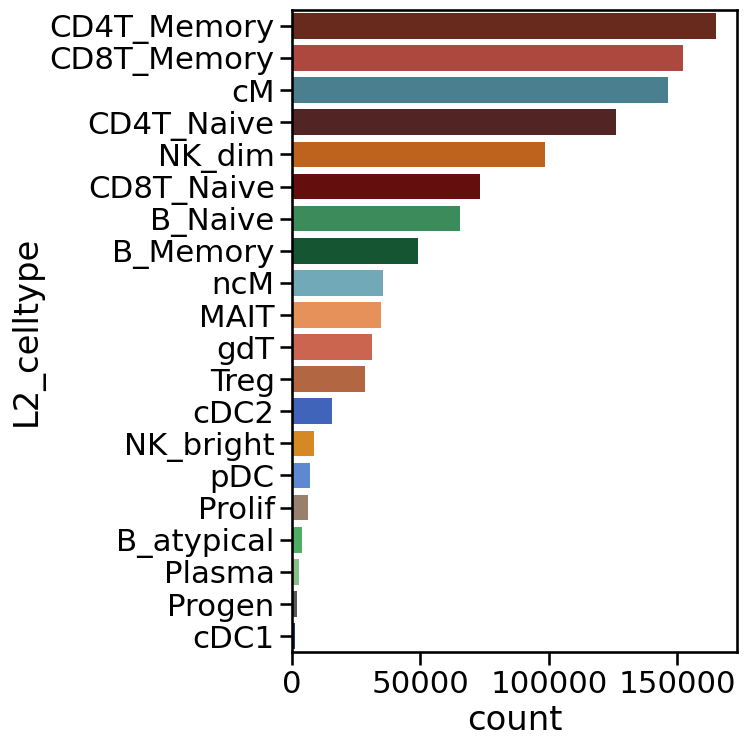

In [28]:
fig, ax = plt.subplots(figsize=(8, 8))
plt_df=pd.DataFrame(df.L2_manual.value_counts())
plt_df['L2_celltype']=plt_df.index
sns.barplot(data=plt_df, y='L2_celltype',x='count',palette=L2_colors)
#plt.title('L2 Cell Types')
plt.tight_layout()

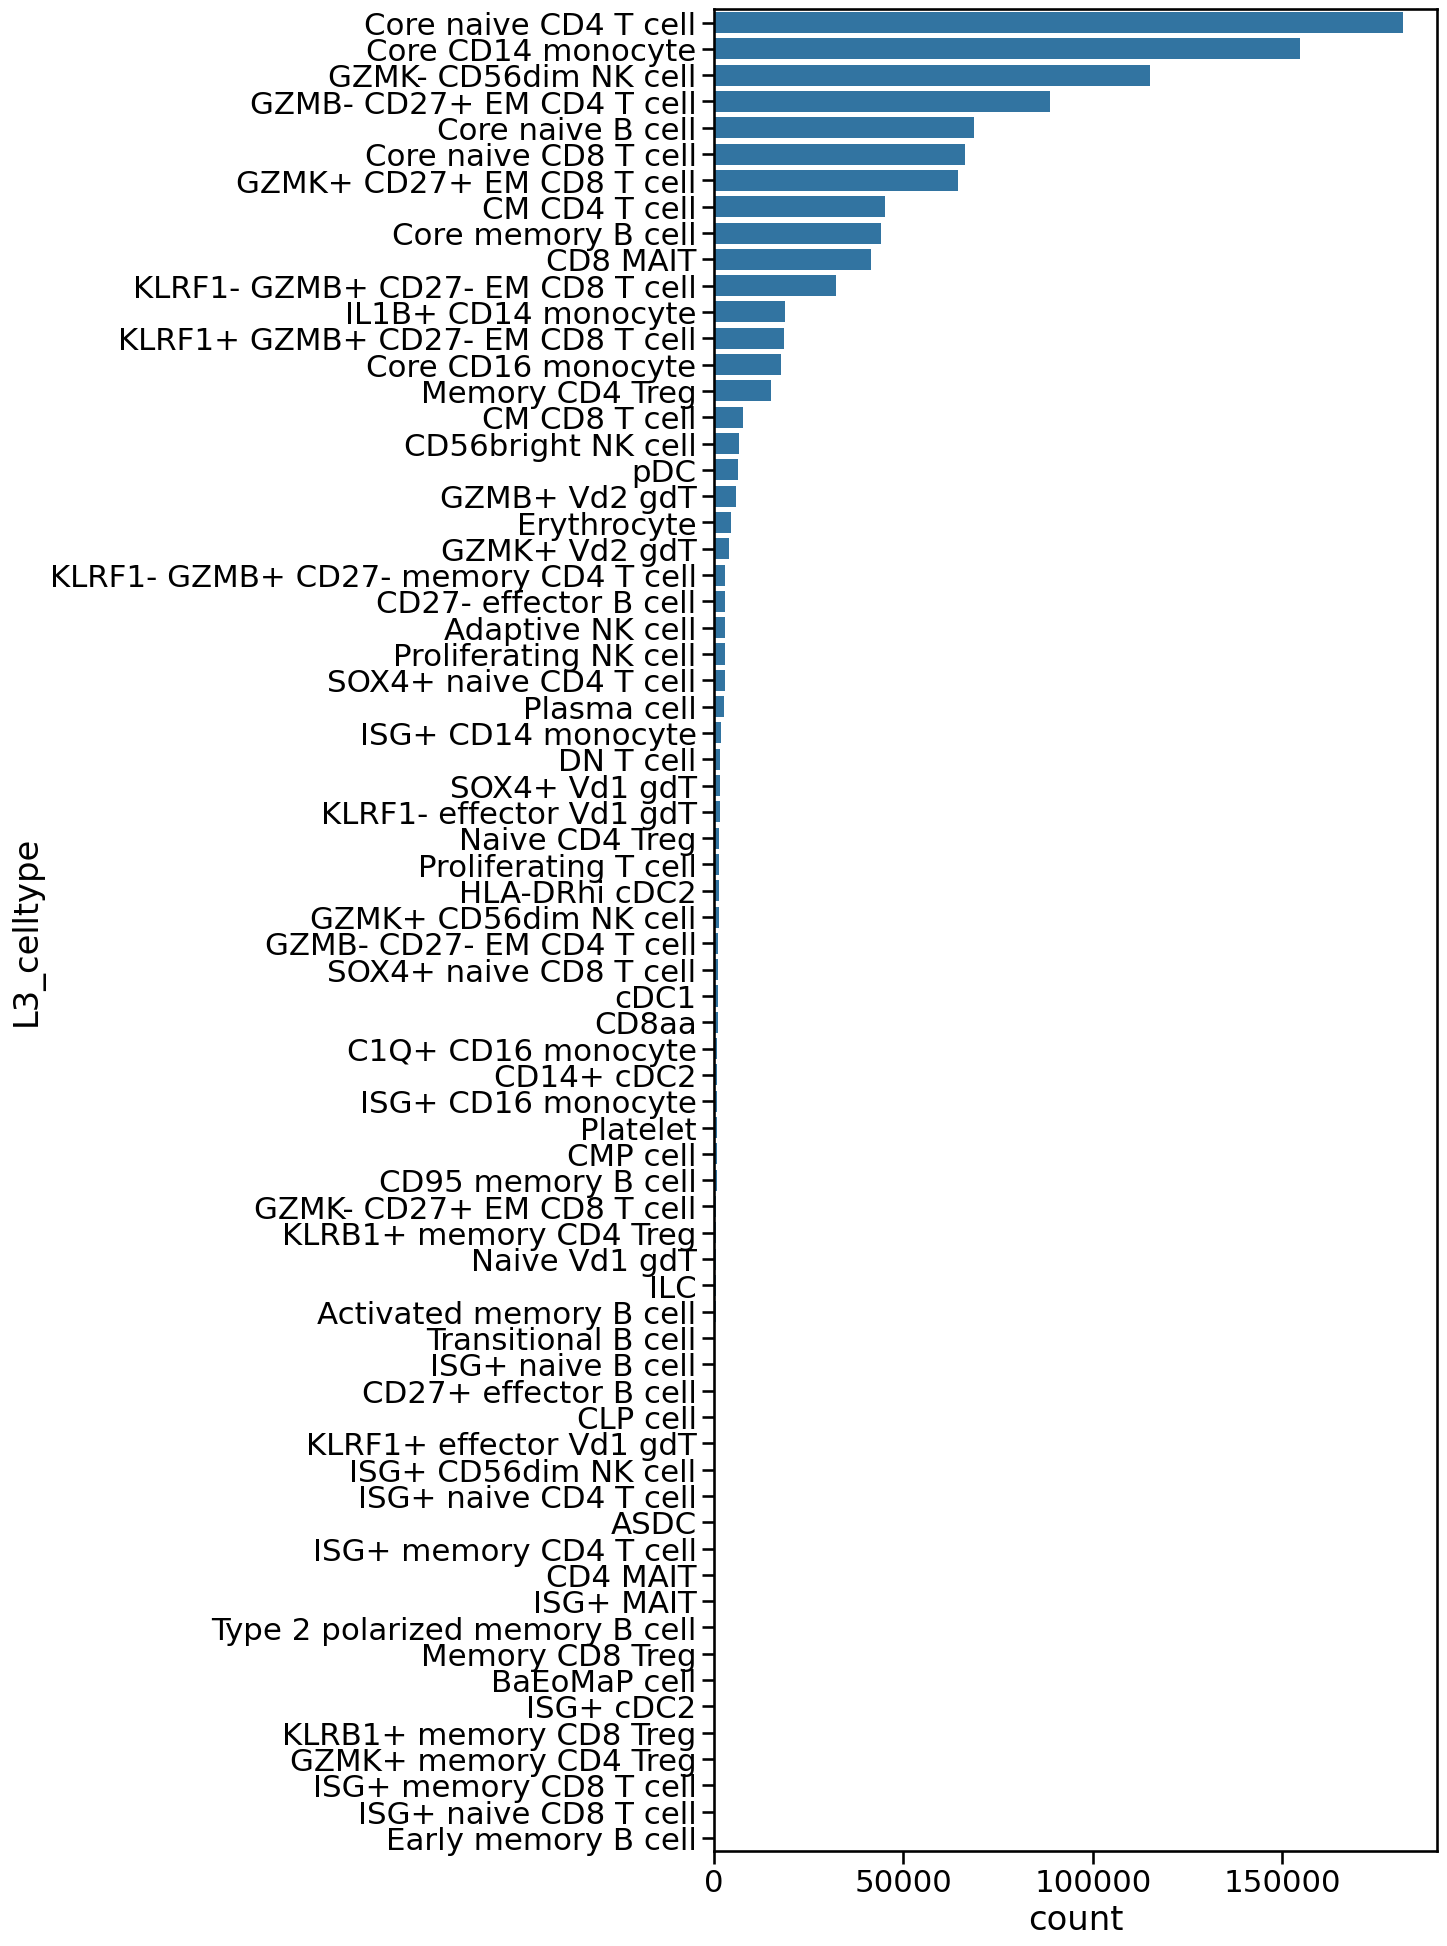

In [64]:

fig, ax = plt.subplots(figsize=(15, 20))
plt_df=pd.DataFrame(df.AIFI_L3_prediction.value_counts())
plt_df['L3_celltype']=plt_df.index
sns.barplot(data=plt_df, y='L3_celltype',x='count')

plt.tight_layout()


In [ ]:
plt_df=pd.DataFrame(df.L1_manual.value_counts())
plt_df['L1_celltype']=plt_df.index
sns.barplot(data=plt_df, y='L1_celltype',x='count',palette=L1_colors)
plt.title('L1 Cell Types')

# Peak counts per gene

In [ ]:
pthresh=5e-8
cells=['B_Memory','B_Naive','CD4T_Naive','CD8T_Naive','cM']
cells=['B_Memory','B_Naive','B_atypical','Plasma',
       'CD4T_Naive','CD4T_Memory','CD8T_Naive','CD8T_Memory','MAIT','gdT','NK_bright','NK_dim',
       'cM','ncM','cDC1','cDC2','pDC']

In [ ]:
sig_dfs=[None] * len(cells)
i=0
for celltype in cells:
    for chr in list(range(1,23)):
        if chr==1:
            data=pd.read_csv(f'/data/processed/GenePeak/scMultiMap/L2/{celltype}/{celltype}_chr{chr}_scMultiMap_nCell_10000.csv.gz')
            cur=data[data['padj']<pthresh][['gene','peak']]
            cur[celltype]=1
        else:
            data=pd.read_csv(f'/data/processed/GenePeak/scMultiMap/L2/{celltype}/{celltype}_chr{chr}_scMultiMap_nCell_10000.csv.gz')
            tmp=data[data['padj']<pthresh][['gene','peak']]
            tmp[celltype]=1
            cur=pd.concat([cur,tmp],axis=0)
        
    sig_dfs[i]=cur
    i+=1

result = reduce(lambda left, right: pd.merge(left, right, on=['gene','peak'], how='outer'), sig_dfs).fillna(0)


In [129]:
result.head()

,gene,peak,B_Memory,B_Naive,B_atypical,Plasma,CD4T_Naive,CD4T_Memory,CD8T_Naive,CD8T_Memory,MAIT,gdT,NK_bright,NK_dim,cM,ncM,cDC1,cDC2,pDC
0,ENSG00000000419,chr20-50030748-50031248,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,ENSG00000000457,chr1-170689430-170689930,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,ENSG00000000460,chr1-169486561-169487061,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,ENSG00000000460,chr1-169677388-169677888,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,ENSG00000000460,chr1-169710923-169711423,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [153]:
peak_gene_cts=[None] * len(cells)
i=0
for celltype in cells:
    cur=pd.DataFrame(result[result[celltype]==1]['gene'].value_counts())
    cur.columns=[celltype]
    
    peak_gene_cts[i]=cur
    i+=1
count_result = reduce(lambda left, right: pd.merge(left, right, left_index=True, right_index=True, how='outer'), peak_gene_cts)   
    

In [154]:
count_result

,B_Memory,B_Naive,B_atypical,Plasma,CD4T_Naive,CD4T_Memory,CD8T_Naive,CD8T_Memory,MAIT,gdT,NK_bright,NK_dim,cM,ncM,cDC1,cDC2,pDC
gene,,,,,,,,,,,,,,,,,
ENSG00000000419,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
ENSG00000000457,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ENSG00000000460,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,2.0,1.0,NaN,NaN,NaN
ENSG00000000938,NaN,NaN,NaN,NaN,NaN,3.0,4.0,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
ENSG00000000971,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSG00000288253,3.0,3.0,NaN,NaN,1.0,1.0,NaN,2.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ENSG00000288302,3.0,2.0,2.0,NaN,3.0,3.0,2.0,2.0,NaN,3.0,NaN,4.0,1.0,NaN,NaN,NaN,1.0
ENSG00000288380,NaN,NaN,2.0,3.0,1.0,NaN,2.0,NaN,2.0,3.0,5.0,2.0,1.0,2.0,1.0,NaN,1.0


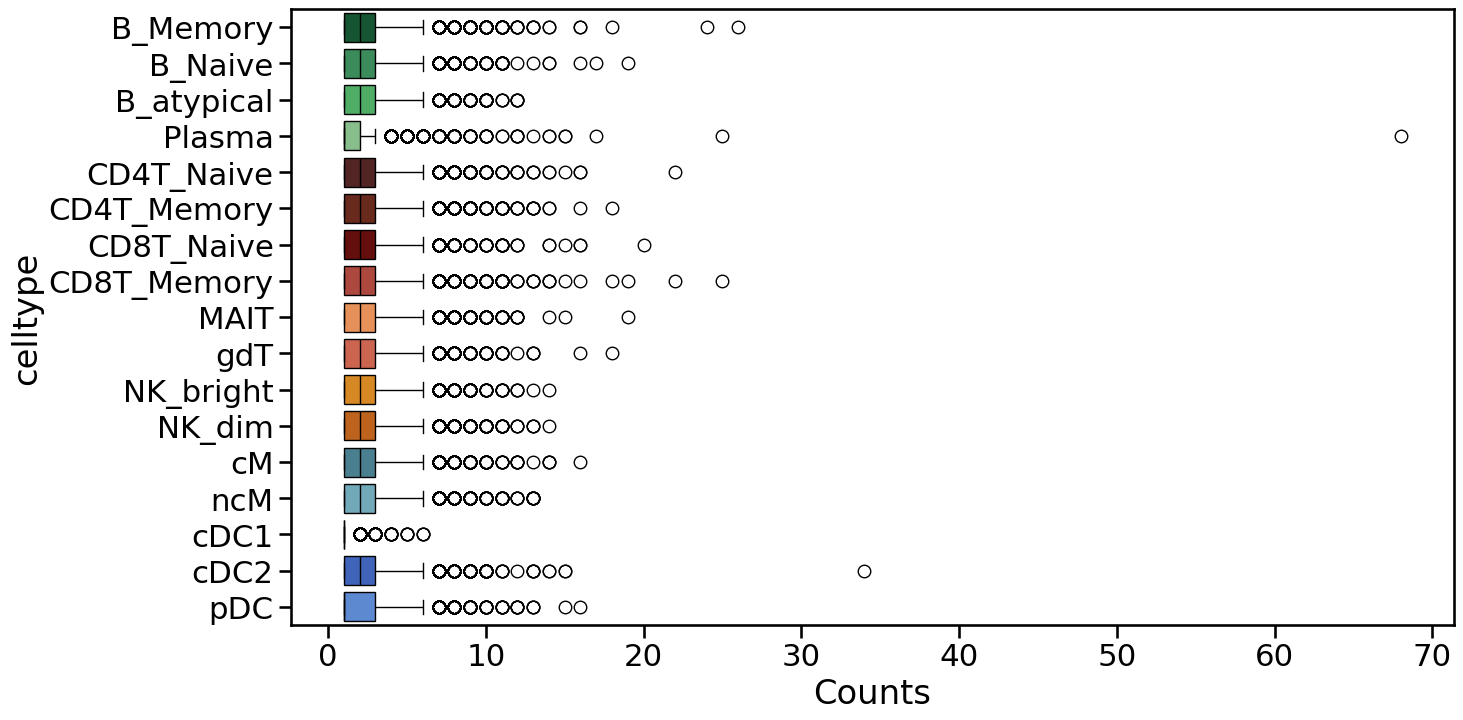

In [175]:
fig, ax = plt.subplots(figsize=(15, 8))
sns.boxplot(count_result,palette=L2_colors, orient='h',ax=ax)
ax.set_xlabel('Counts')
ax.set_ylabel('celltype')
#ax.set_xlim(left=0,right=30)
#ax.set_xscale('log')
plt.show()

In [121]:
test=pd.DataFrame(result[result['B_Memory']==1]['gene'].value_counts())

In [146]:
test.columns

Index(['count'], dtype='object')

In [143]:
test['count'].astype(int).median()

2.0

<Axes: xlabel='count'>

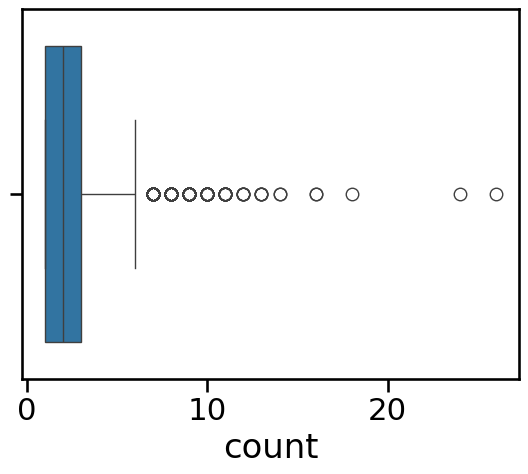

In [127]:
sns.boxplot(data=test,x='count')

# Get peak counts across cell  types

In [111]:
pthresh=5e-8
cells=['B_Memory','B_Naive','CD4T_Naive','CD8T_Naive','cM']
cells=['B_Memory','B_Naive','B_atypical','Plasma',
       'CD4T_Naive','CD4T_Memory','CD8T_Naive','CD8T_Memory','MAIT','gdT','NK_bright','NK_dim',
       'cM','ncM','cDC1','cDC2','pDC']

In [112]:
sig_dfs=[None] * len(cells)
i=0
for celltype in cells:
    for chr in list(range(1,23)):
        if chr==1:
            data=pd.read_csv(f'/data/processed/GenePeak/scMultiMap/L2/{celltype}/{celltype}_chr{chr}_scMultiMap_nCell_10000.csv.gz')
            cur=data[data['padj']<pthresh][['gene','peak']]
            cur[celltype]=1
        else:
            data=pd.read_csv(f'/data/processed/GenePeak/scMultiMap/L2/{celltype}/{celltype}_chr{chr}_scMultiMap_nCell_10000.csv.gz')
            tmp=data[data['padj']<pthresh][['gene','peak']]
            tmp[celltype]=1
            cur=pd.concat([cur,tmp],axis=0)
        
    sig_dfs[i]=cur
    i+=1

result = reduce(lambda left, right: pd.merge(left, right, on=['gene','peak'], how='outer'), sig_dfs).fillna(0)


In [113]:
counts=pd.DataFrame(result[cells].sum())
counts.columns=['counts']
counts['celltype']=counts.index
counts

,counts,celltype
B_Memory,19286.0,B_Memory
B_Naive,16258.0,B_Naive
B_atypical,10430.0,B_atypical
Plasma,7522.0,Plasma
CD4T_Naive,15035.0,CD4T_Naive
CD4T_Memory,16823.0,CD4T_Memory
CD8T_Naive,13335.0,CD8T_Naive
CD8T_Memory,17207.0,CD8T_Memory
MAIT,15888.0,MAIT
gdT,15477.0,gdT


/tmp/ipykernel_1354/507469305.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(counts,y='celltype',x='counts',palette=L2_colors)


<Axes: xlabel='counts', ylabel='celltype'>

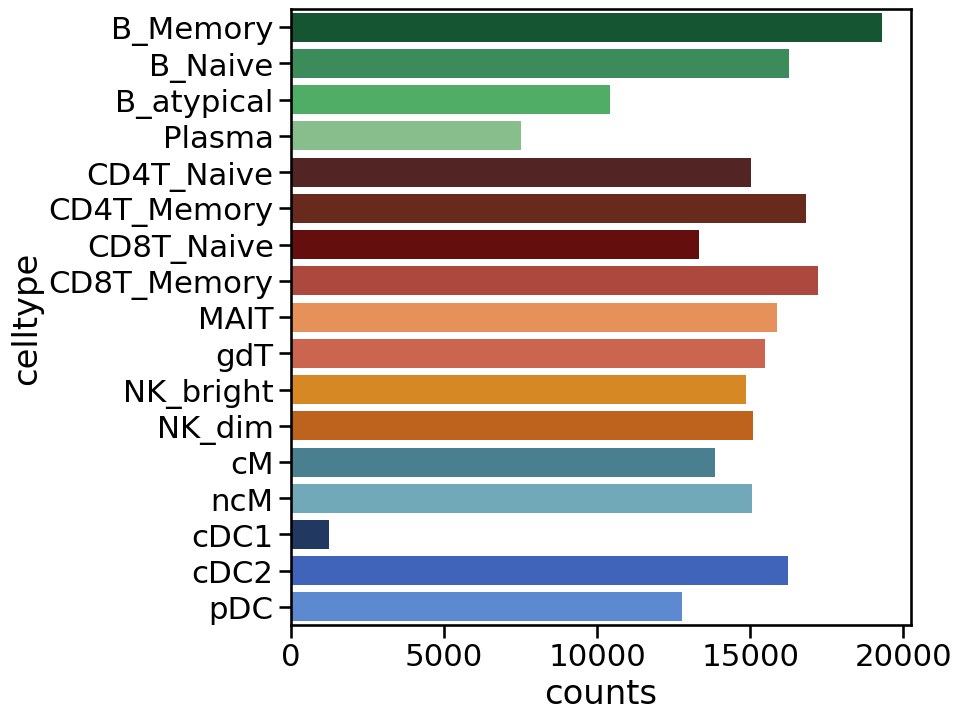

In [114]:
fig = plt.figure(figsize=(8, 8))

sns.barplot(counts,y='celltype',x='counts',palette=L2_colors)

/tmp/ipykernel_1354/507469305.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(counts,y='celltype',x='counts',palette=L2_colors)


<Axes: xlabel='counts', ylabel='celltype'>

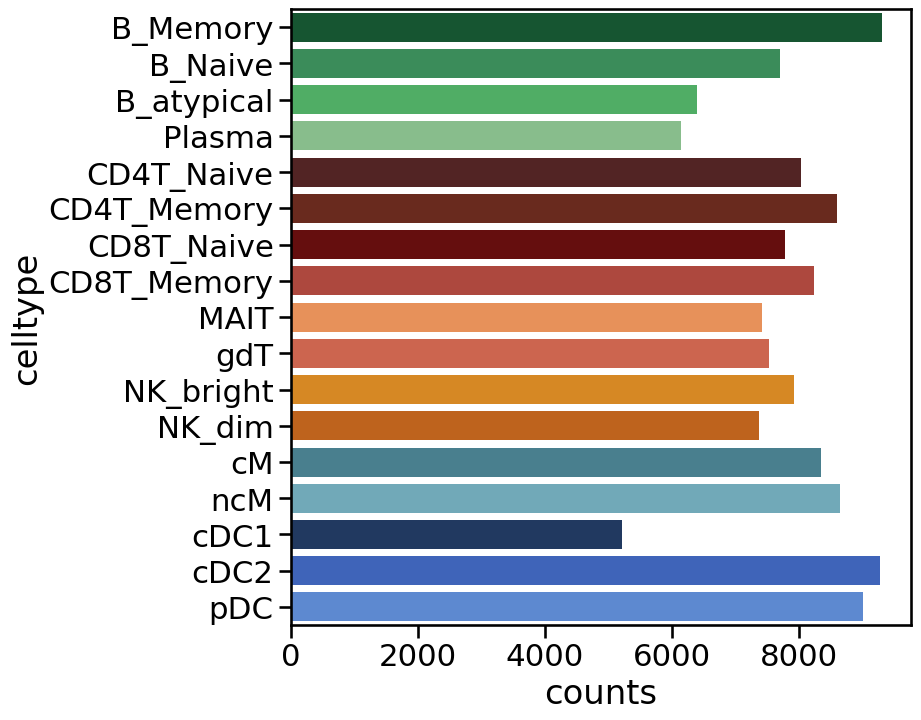

In [100]:
fig = plt.figure(figsize=(8, 8))

sns.barplot(counts,y='celltype',x='counts',palette=L2_colors)

/home/ubuntu/miniconda3/envs/tensorQTL/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/ubuntu/miniconda3/envs/tensorQTL/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we ar

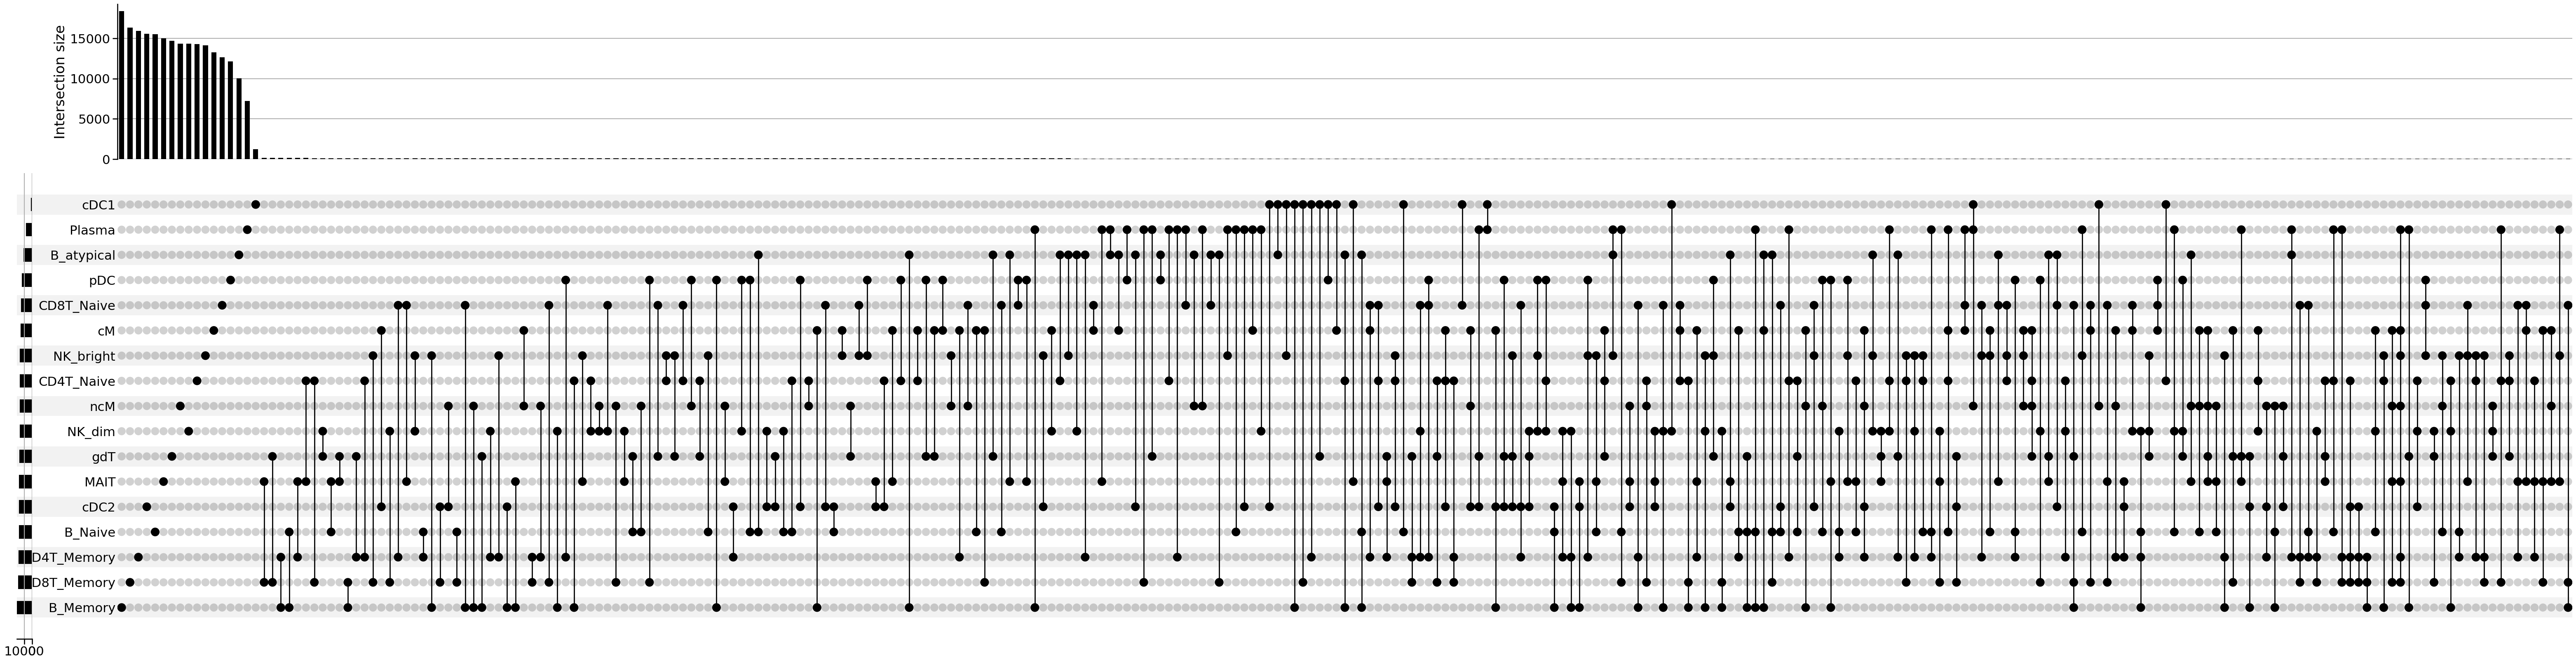

In [115]:
df_bool=result[cells].astype(bool)
df_upset=df_bool.set_index(list(df_bool.columns))

fig = plt.figure(figsize=(80, 20))
plot(df_upset, fig=fig,element_size=None, sort_by='cardinality')
plt.show()

<Axes: xlabel='cor', ylabel='Count'>

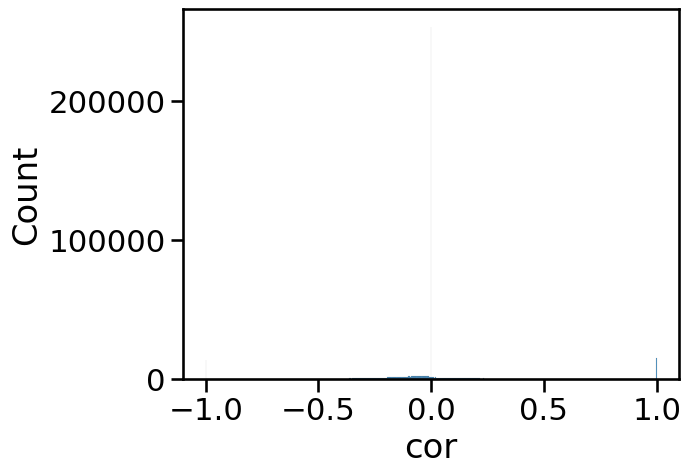

In [20]:
sns.histplot(data=data, x='cor')

<Axes: xlabel='cor', ylabel='Count'>

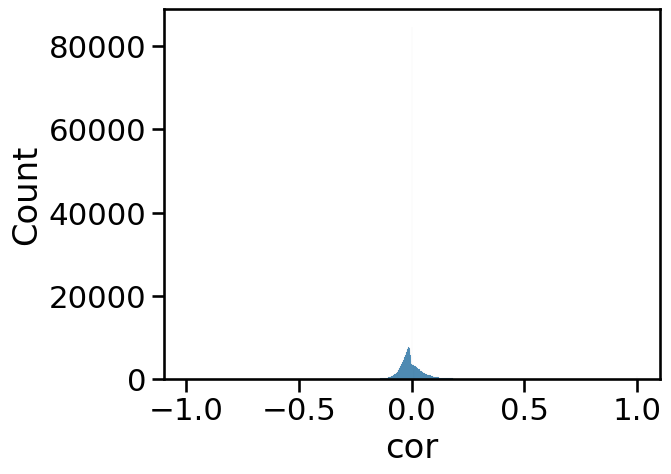

In [19]:
sns.histplot(data=data2, x='cor')

/home/ubuntu/miniconda3/envs/tensorQTL/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/ubuntu/miniconda3/envs/tensorQTL/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we ar

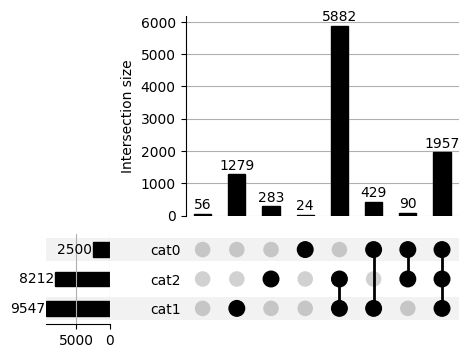

In [1]:
import pandas as pd
from upsetplot import generate_counts, plot
import matplotlib.pyplot as plt

# 1. Generate or create some sample data
# This creates a Series with a MultiIndex representing set membership
example_data = generate_counts()

# 2. Create the plot
plot(example_data, orientation='horizontal', show_counts=True)

# 3. Display
plt.show()

In [2]:
example_data

cat0   cat1   cat2 
False  False  False      56
              True      283
       True   False    1279
              True     5882
True   False  False      24
              True       90
       True   False     429
              True     1957
Name: value, dtype: int64